# Notebook 11 – Model Evaluation for Computer Vision



In [1]:
import time
import numpy as np
import torch
from torch import nn
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)

PyTorch: 2.14.0+cpu | device: cpu


## Concept
Accuracy may hide failure on rare classes. Precision is the fraction of predicted positives that are correct; recall is the fraction of actual positives found; F1 balances them. State multiclass averaging (macro, weighted, micro). ROC-AUC uses scores/probabilities and can use one-vs-rest; it does not replace thresholds, class-wise metrics, or confusion matrices.

              precision    recall  f1-score   support

           0      1.000     0.978     0.989        45
           1      0.894     0.913     0.903        46
           2      1.000     1.000     1.000        44
           3      0.979     1.000     0.989        46
           4      0.938     1.000     0.968        45
           5      0.978     0.957     0.967        46
           6      0.977     0.956     0.966        45
           7      0.978     1.000     0.989        45
           8      0.927     0.884     0.905        43
           9      0.955     0.933     0.944        45

    accuracy                          0.962       450
   macro avg      0.962     0.962     0.962       450
weighted avg      0.962     0.962     0.962       450

per-class accuracy: [0.978 0.913 1.    1.    1.    0.957 0.956 1.    0.884 0.933]
macro OvR ROC-AUC: 0.999


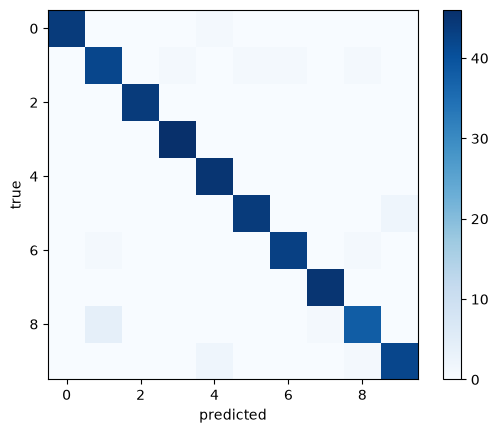

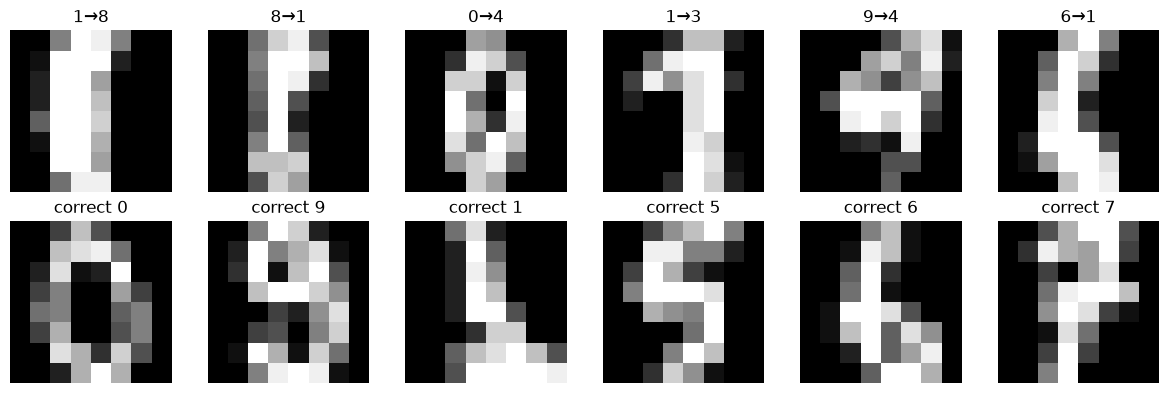

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,confusion_matrix,roc_auc_score
import matplotlib.pyplot as plt
d=load_digits(); splitter=StratifiedShuffleSplit(n_splits=1,test_size=.25,random_state=42)
train_idx,test_idx=next(splitter.split(d.data,d.target))
xtr,xte,ytr,yte=d.data[train_idx]/16,d.data[test_idx]/16,d.target[train_idx],d.target[test_idx]
clf=LogisticRegression(max_iter=1000).fit(xtr,ytr); pred=clf.predict(xte); probs=clf.predict_proba(xte)
print(classification_report(yte,pred,digits=3)); cm=confusion_matrix(yte,pred); print('per-class accuracy:',np.round(cm.diagonal()/cm.sum(axis=1),3))
print('macro OvR ROC-AUC:',round(roc_auc_score(yte,probs,multi_class='ovr',average='macro'),3))
plt.imshow(cm,cmap='Blues'); plt.xlabel('predicted'); plt.ylabel('true'); plt.colorbar(); plt.show()
wrong=np.flatnonzero(pred!=yte); right=np.flatnonzero(pred==yte); fig,axes=plt.subplots(2,6,figsize=(12,4))
for ax,i in zip(axes[0],wrong[:6]): ax.imshow(d.images[test_idx[i]],cmap='gray'); ax.set_title(f'{yte[i]}→{pred[i]}'); ax.axis('off')
for ax,i in zip(axes[1],right[:6]): ax.imshow(d.images[test_idx[i]],cmap='gray'); ax.set_title(f'correct {pred[i]}'); ax.axis('off')
plt.tight_layout(); plt.show()

## Interpret errors
For every major confusion ask: **What went wrong? Why might it have happened? How could it be improved?** Review actual images, class support, and confidence. Ambiguous handwriting, class overlap, preprocessing, and imbalance are hypotheses to check. Visualize correct and incorrect examples from the exact test indices; do not let indexing mistakes mislabel images.